In [ ]:
# Import Modules
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA

In [ ]:
# 1. Load Time Series Dataset
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
data = pd.read_csv(url)
print(data)
# convert month column to datatime
data['Month'] = pd.to_datetime(data['Month'])

# set as index
data.set_index('Month', inplace=True)

print(data.head(10))

       Month  Passengers
0    1949-01         112
1    1949-02         118
2    1949-03         132
3    1949-04         129
4    1949-05         121
..       ...         ...
139  1960-08         606
140  1960-09         508
141  1960-10         461
142  1960-11         390
143  1960-12         432

[144 rows x 2 columns]
            Passengers
Month                 
1949-01-01         112
1949-02-01         118
1949-03-01         132
1949-04-01         129
1949-05-01         121
1949-06-01         135
1949-07-01         148
1949-08-01         148
1949-09-01         136
1949-10-01         119


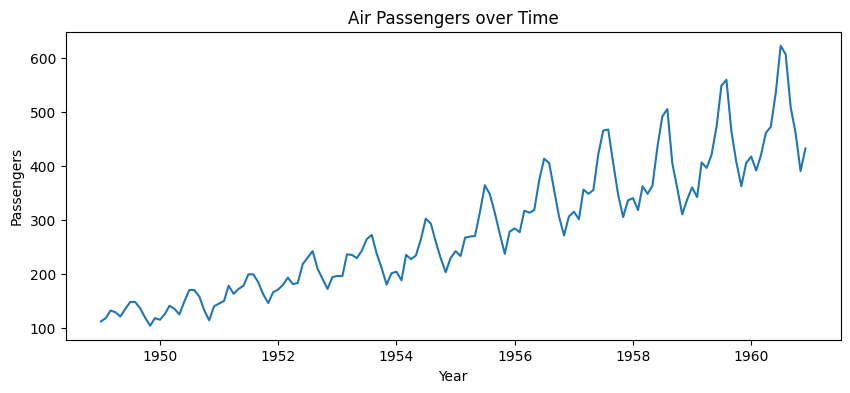

In [ ]:
# 2. Visualize Time Series
plt.figure(figsize=(10,4))
plt.plot(data['Passengers'])
plt.title("Air Passengers over Time")
plt.xlabel("Year")
plt.ylabel("Passengers")
plt.show()

In [ ]:
# 3. Check Stationarity (ADF Test)
result = adfuller(data['Passengers'])
print("ADF Statistic: ", result[0])
print("p-value: ", result[1])

ADF Statistic:  0.8153688792060498
p-value:  0.991880243437641


In [ ]:
# 4. Fit ARIMA Model
model = ARIMA(data['Passengers'],order=(2,1,2))
model_fit = model.fit()

print(model_fit.summary())

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  144
Model:                 ARIMA(2, 1, 2)   Log Likelihood                -671.673
Date:                Tue, 18 Nov 2025   AIC                           1353.347
Time:                        20:04:40   BIC                           1368.161
Sample:                    01-01-1949   HQIC                          1359.366
                         - 12-01-1960                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.6850      0.020     83.060      0.000       1.645       1.725
ar.L2         -0.9548      0.017    -55.420      0.000      -0.989      -0.921
ma.L1         -1.8432      0.124    -14.814      0.0

In [ ]:
# 5. Forecast Next 12 Months
forecast = model_fit.forecast(steps=12)
print("\nForecasted Values:\n", forecast)


Forecasted Values:
 1961-01-01    439.854863
1961-02-01    465.296545
1961-03-01    500.666051
1961-04-01    535.971401
1961-05-01    561.689094
1961-06-01    571.312667
1961-07-01    562.972100
1961-08-01    539.729052
1961-09-01    508.528057
1961-10-01    478.147364
1961-11-01    456.747520
1961-12-01    449.697306
Freq: MS, Name: predicted_mean, dtype: float64


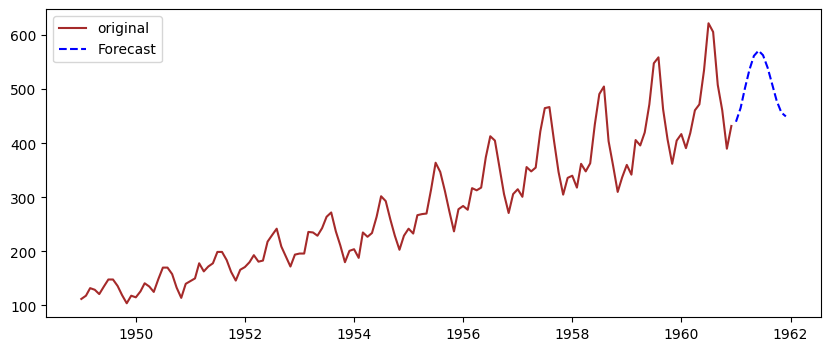

In [ ]:
from matplotlib.lines import lineStyles
plt.figure(figsize=(10,4))
plt.plot(data['Passengers'], label="original", color='brown')
plt.plot(forecast, label="Forecast", linestyle='--', color='blue')
plt.legend()
plt.show()